# 脑转移瘤全时序演化生成（优化版）

**目标**：输出「黑色肿瘤随时间扩散/增长」的完整时间序列，而不是单张重建。

方法：
1. 复用优化后的 3D VAE + DiT（`brain_tumor_ldm.pt`）；
2. **两阶段扩散**：网格步 k 越大 → 注入噪声的起点越高 → 扩散模型驱动的演化越强；
3. **暗病灶生长先验**：检测低强度（黑色）病灶，按生长律进度单调加深、扩张；
4. 输出三视图 × 9 帧的时序大图 + nii.gz 序列 + 病灶面积增长曲线。

In [13]:
import os, math, random, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'Hiragino Sans GB', 'Songti SC', 'Noto Sans CJK SC', 'WenQuanYi Zen Hei']
plt.rcParams['axes.unicode_minus'] = False

_local = Path('/Users/chris/Desktop')
NOTEBOOK_DIR = _local if _local.exists() else Path('/root/autodl-tmp')
DATA_ROOT = NOTEBOOK_DIR / 'BRAINMETASTASIS'
TEST_ROOT = DATA_ROOT / 'test'
IMG_SIZE = (64, 64, 64)
LATENT_CH = 4
SEED = 42
GRID_STEPS = 8            # 时序帧数（t=0..8）
GROWTH_DARKEN = 0.32      # 病灶最终变暗幅度
CHANGE_STRENGTH = 0.55    # 扩散结构变化强度

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), '| VRAM %.0f GB' % (torch.cuda.get_device_properties(0).total_memory/1e9))


device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | VRAM 102 GB


In [2]:
# ---------- 数据加载 + 缓存 ----------
def _slice_number(path):
    stem = path.stem.lower()
    return int(stem.rsplit('_z', 1)[-1]) if '_z' in stem else 0

def _case_dirs(root_dir):
    return sorted(p for p in Path(root_dir).expanduser().glob('Mets_*') if p.is_dir())

def _load_png_volume(case_dir, modality='t1_gd'):
    files = sorted((case_dir / modality).glob('*.png'), key=_slice_number)
    slices = []
    for path in files:
        im = Image.open(path).convert('L').resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
        slices.append(np.asarray(im, dtype=np.float32) / 255.0)
    vol = torch.from_numpy(np.stack(slices, axis=0)).unsqueeze(0).unsqueeze(0)
    return F.interpolate(vol, size=IMG_SIZE, mode='trilinear', align_corners=False).squeeze(0)

@torch.no_grad()
def cache_cases(root):
    return torch.stack([_load_png_volume(c) for c in _case_dirs(root)])

test_vols = cache_cases(TEST_ROOT)
test_cases = _case_dirs(TEST_ROOT)
print('test cases:', len(test_cases), tuple(test_vols.shape))

test cases: 51 (51, 1, 64, 64, 64)


In [3]:
# ---------- 优化模型定义（与优化实验一致） ----------
class ResBlock3D(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.n1 = nn.GroupNorm(8, ch); self.c1 = nn.Conv3d(ch, ch, 3, padding=1)
        self.n2 = nn.GroupNorm(8, ch); self.c2 = nn.Conv3d(ch, ch, 3, padding=1)
    def forward(self, x):
        return x + self.c2(F.silu(self.n2(self.c1(F.silu(self.n1(x))))))

class VAE3DOpt(nn.Module):
    def __init__(self, in_ch=1, latent_ch=LATENT_CH, base=32):
        super().__init__()
        self.conv_in = nn.Conv3d(in_ch, base, 3, padding=1)
        self.d1 = nn.Sequential(ResBlock3D(base), nn.Conv3d(base, base*2, 3, stride=2, padding=1))
        self.d2 = nn.Sequential(ResBlock3D(base*2), nn.Conv3d(base*2, base*4, 3, stride=2, padding=1))
        self.mid = nn.Sequential(ResBlock3D(base*4), ResBlock3D(base*4))
        self.norm_out = nn.GroupNorm(8, base*4)
        self.mu_head = nn.Conv3d(base*4, latent_ch, 3, padding=1)
        self.lv_head = nn.Conv3d(base*4, latent_ch, 3, padding=1)
        self.z_in = nn.Conv3d(latent_ch, base*4, 3, padding=1)
        self.mid_d = nn.Sequential(ResBlock3D(base*4), ResBlock3D(base*4))
        self.u1 = nn.Sequential(ResBlock3D(base*4), nn.ConvTranspose3d(base*4, base*2, 3, stride=2, padding=1, output_padding=1))
        self.u2 = nn.Sequential(ResBlock3D(base*2), nn.ConvTranspose3d(base*2, base, 3, stride=2, padding=1, output_padding=1))
        self.norm_d = nn.GroupNorm(8, base)
        self.out = nn.Conv3d(base, in_ch, 3, padding=1)
        self.register_buffer('z_mean', torch.zeros(1, latent_ch, 1, 1, 1))
        self.register_buffer('z_std', torch.ones(1, latent_ch, 1, 1, 1))
        self.warmed = False
    def encode(self, x):
        h = self.mid(self.d2(self.d1(self.conv_in(x))))
        h = F.silu(self.norm_out(h))
        mu, lv = self.mu_head(h), self.lv_head(h)
        z = mu + torch.randn_like(mu) * torch.exp(0.5*lv) if self.training else mu
        with torch.no_grad():
            m = mu.mean(dim=(0,2,3,4), keepdim=True)
            s = (mu.var(dim=(0,2,3,4), unbiased=False, keepdim=True)+1e-6).sqrt()
            if not self.warmed:
                self.z_mean.copy_(m); self.z_std.copy_(s); self.warmed = True
            else:
                self.z_mean.mul_(0.99).add_(m*0.01); self.z_std.mul_(0.99).add_(s*0.01)
        return (z - self.z_mean) / self.z_std
    def decode(self, z_norm):
        z = z_norm * self.z_std + self.z_mean
        h = self.mid_d(self.z_in(z)); h = self.u1(h); h = self.u2(h)
        return torch.sigmoid(self.out(F.silu(self.norm_d(h))))

def timestep_embedding(t, dim=256, max_period=10000.0):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, dtype=torch.float32, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=-1)

class AdaDiTBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim*mlp_ratio)), nn.GELU(), nn.Linear(int(dim*mlp_ratio), dim))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(dim, 6*dim))
        nn.init.constant_(self.ada[-1].weight, 0)
        nn.init.constant_(self.ada[-1].bias, 0)
    def forward(self, x, c):
        sh_a, s_a, g_a, sh_m, s_m, g_m = self.ada(c).chunk(6, dim=1)
        q = self.norm1(x) * (1 + s_a.unsqueeze(1)) + sh_a.unsqueeze(1)
        x = x + g_a.unsqueeze(1) * self.attn(q, q, q, need_weights=False)[0]
        m = self.norm2(x) * (1 + s_m.unsqueeze(1)) + sh_m.unsqueeze(1)
        return x + g_m.unsqueeze(1) * self.mlp(m)

class DiT3DOpt(nn.Module):
    def __init__(self, latent_ch=LATENT_CH, cond_dim=LATENT_CH, dim=192, depth=6, num_heads=6, patch_size=2, T=1000):
        super().__init__()
        self.dim, self.patch_size, self.T = dim, patch_size, T
        self.grid = (8, 8, 8)
        self.num_tokens = 512
        patch_dim = latent_ch * patch_size ** 3
        self.patch_embed = nn.Conv3d(latent_ch, dim, patch_size, stride=patch_size)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_tokens, dim))
        nn.init.normal_(self.pos_embed, std=0.02)
        self.time_mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.cond_emb = nn.Sequential(nn.Linear(cond_dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.blocks = nn.ModuleList([AdaDiTBlock(dim, num_heads) for _ in range(depth)])
        self.final_norm = nn.LayerNorm(dim, elementwise_affine=False)
        self.unpatch = nn.Linear(dim, patch_dim)
        nn.init.zeros_(self.unpatch.weight)
        nn.init.zeros_(self.unpatch.bias)
    def forward(self, z, t, cond):
        B, C, H, W, D = z.shape
        tokens = self.patch_embed(z).flatten(2).transpose(1, 2)
        te = timestep_embedding(t.view(B).float() / self.T, dim=self.dim).to(z.dtype)
        c = self.time_mlp(te) + self.cond_emb(cond)
        tokens = tokens + self.pos_embed
        for blk in self.blocks:
            tokens = blk(tokens, c)
        pv = self.unpatch(self.final_norm(tokens))
        pv = pv.reshape(B, *self.grid, C, self.patch_size, self.patch_size, self.patch_size)
        return pv.permute(0, 4, 1, 5, 2, 6, 3, 7).reshape(B, C, H, W, D)

def cosine_betas(T, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float32)
    ab = torch.cos(((steps / T + s) / (1 + s)) * math.pi / 2) ** 2
    ab = ab / ab[0]
    return torch.clip(1 - ab[1:] / ab[:-1], 0, 0.999)

print('模型定义 OK')

模型定义 OK


In [4]:
# ---------- 加载优化权重 ----------
ckpt_path = NOTEBOOK_DIR / 'brain_tumor_ldm.pt'
ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=True)
vae = VAE3DOpt().to(device)
unet = DiT3DOpt(dim=192, depth=6, num_heads=6, T=1000).to(device)
vae.load_state_dict(ckpt['vae'])
unet.load_state_dict(ckpt['unet'])
betas = ckpt.get('betas', cosine_betas(1000)).to(device)
T = int(ckpt.get('T', 1000))
vae.eval(); unet.eval()
print('已加载优化权重:', ckpt_path)
print('历史指标:', {k: (round(v,4) if isinstance(v,float) else v) for k,v in ckpt.get('metrics',{}).items()})

已加载优化权重: /root/autodl-tmp/brain_tumor_ldm.pt
历史指标: {'vae': {'mse': 0.0002853689184121322, 'mae': 0.0050450781515489025, 'psnr': 35.445933307910494, 'ssim': 0.984333947300911}, 'ldm_test_mse': 0.1707, 'baseline_vae': {'mse': 0.02278792718425393, 'mae': 0.05548641737550497, 'psnr': 16.42295176942549, 'ssim': 0.7293086449305216}, 'baseline_ldm_mse': 0.4789}


In [5]:
# ---------- 续训 DiT 40 epochs：进一步提升生成画质 ----------
@torch.no_grad()
def cache_train(root):
    return torch.stack([_load_png_volume(c) for c in _case_dirs(root)])

train_vols = cache_train(DATA_ROOT / 'train')
def augment_batch(x):
    for axis in (2, 3, 4):
        if random.random() < 0.5:
            x = torch.flip(x, dims=(axis,))
    x = x * random.uniform(0.96, 1.04) + random.uniform(-0.02, 0.02)
    return (x + torch.randn_like(x) * 0.005).clamp(0, 1)

alpha = 1 - betas
ab = torch.cumprod(alpha, dim=0)
opt = torch.optim.AdamW(unet.parameters(), lr=1e-4, weight_decay=1e-5)
n = len(train_vols)
unet.train(); vae.eval()
for epoch in range(40):
    idx = list(range(n)) * 4
    random.Random(1000+epoch).shuffle(idx)
    tot = 0.0; t0 = time.time()
    for s in range(0, len(idx), 4):
        x = augment_batch(train_vols[idx[s:s+4]]).to(device)
        with torch.no_grad():
            z0 = vae.encode(x)
            cond = F.adaptive_avg_pool3d(z0, 1).flatten(1)
        t = torch.randint(0, T, (x.shape[0],), device=device)
        eps = torch.randn_like(z0)
        zt = torch.sqrt(ab[t].view(-1,1,1,1,1))*z0 + torch.sqrt(1-ab[t].view(-1,1,1,1,1))*eps
        loss = F.mse_loss(unet(zt, t, cond), eps)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
        opt.step()
        tot += loss.item()
    print(f'续训 epoch {epoch+1}/40 | mse={tot/(len(idx)//4):.6f} | 用时{time.time()-t0:.0f}s', flush=True)

# 更新 checkpoint
ckpt['unet'] = unet.state_dict()
torch.save(ckpt, ckpt_path)
print('续训完成，权重已更新:', ckpt_path)

续训 epoch 1/40 | mse=0.209116 | 用时3s
续训 epoch 2/40 | mse=0.214393 | 用时2s
续训 epoch 3/40 | mse=0.209513 | 用时2s
续训 epoch 4/40 | mse=0.209086 | 用时2s
续训 epoch 5/40 | mse=0.197479 | 用时2s
续训 epoch 6/40 | mse=0.186992 | 用时2s
续训 epoch 7/40 | mse=0.210142 | 用时2s
续训 epoch 8/40 | mse=0.197131 | 用时2s
续训 epoch 9/40 | mse=0.193772 | 用时2s
续训 epoch 10/40 | mse=0.206785 | 用时2s
续训 epoch 11/40 | mse=0.207990 | 用时2s
续训 epoch 12/40 | mse=0.194052 | 用时2s
续训 epoch 13/40 | mse=0.206999 | 用时2s
续训 epoch 14/40 | mse=0.197113 | 用时2s
续训 epoch 15/40 | mse=0.208628 | 用时2s
续训 epoch 16/40 | mse=0.208007 | 用时2s
续训 epoch 17/40 | mse=0.199262 | 用时2s
续训 epoch 18/40 | mse=0.217801 | 用时2s
续训 epoch 19/40 | mse=0.219341 | 用时2s
续训 epoch 20/40 | mse=0.189078 | 用时2s
续训 epoch 21/40 | mse=0.216164 | 用时2s
续训 epoch 22/40 | mse=0.198416 | 用时2s
续训 epoch 23/40 | mse=0.207432 | 用时2s
续训 epoch 24/40 | mse=0.211315 | 用时2s
续训 epoch 25/40 | mse=0.193112 | 用时2s
续训 epoch 26/40 | mse=0.208103 | 用时2s
续训 epoch 27/40 | mse=0.198867 | 用时2s
续训 epoch 2

In [6]:
# ---------- 暗病灶（黑色肿瘤）检测 ----------
def dark_lesion_mask(vol):
    v = vol[0] if vol.ndim == 4 else vol
    brain = (v > 0.04).float()
    vals = v[brain > 0]
    if vals.numel() == 0:
        return brain
    lo = torch.quantile(vals, 0.30)                      # 低强度阈值
    dark = torch.sigmoid((lo - v) / 0.05) * brain        # 暗概率
    _k = torch.ones(1, 1, 5, 5, 5, device=v.device) / 125.0
    dark = F.conv3d(dark[None, None], _k, padding=2)[0, 0]
    # 以暗概率最大点为种子，做高斯局域化 -> 紧凑病灶
    seed = torch.argmax(dark)
    sz, sy, sx = torch.unravel_index(seed, dark.shape)
    zz = torch.arange(64, dtype=torch.float32, device=v.device)
    zc, yc, xc = zz - float(sz), zz - float(sy), zz - float(sx)
    Z, Y, X = torch.meshgrid(zc, yc, xc, indexing='ij')
    gauss = torch.exp(-(Z*Z + Y*Y + X*X) / (2 * 6.0**2))
    mask = (gauss * dark).clamp(0, 1)
    mask = mask / mask.max().clamp_min(1e-6)
    return mask

def growth_progress(k, N):
    return float(k) / float(N)                           # 线性生长律（可替换为指数律）

print('病灶检测函数 OK')

病灶检测函数 OK


In [7]:
# ---------- DDIM 条件采样 ----------
@torch.no_grad()
def ddim_segment(unet, z, cond, t_start, steps=50):
    t0_ab = ab[t_start]
    z = torch.sqrt(t0_ab)*z + torch.sqrt(1-t0_ab)*torch.randn_like(z)
    ts = torch.linspace(t_start, 0, steps+1, device=device).long()
    for i in range(steps):
        t, tn = ts[i], ts[i+1]
        tv = torch.full((z.shape[0],), t, device=device, dtype=torch.long)
        eps = unet(z, tv, cond)
        ab_t = ab[t].view(1,1,1,1,1); ab_n = ab[tn].view(1,1,1,1,1)
        x0 = (z - torch.sqrt(1-ab_t)*eps) / torch.sqrt(ab_t).clamp_min(1e-8)
        z = torch.sqrt(ab_n)*x0 + torch.sqrt(1-ab_n)*eps
    return z

@torch.no_grad()
def generate_timeline(source, grid_steps=GRID_STEPS):
    '''两阶段扩散 + 暗病灶生长 -> 全时序序列'''
    vae.eval(); unet.eval()
    z0 = vae.encode(source.to(device))
    cond = F.adaptive_avg_pool3d(z0, 1).flatten(1)
    brain = (source[0].to(device) > 0.04).float()
    lesion = dark_lesion_mask(source[0].to(device))       # (64,64,64)

    frames = [source[0].to(device).clone()]
    for k in range(1, grid_steps + 1):
        p = growth_progress(k, grid_steps)
        t_start1 = int(T * (0.06 + 0.70 * p))             # 阶段1：越晚期噪声起点越高
        zk = ddim_segment(unet, z0, cond, t_start1, steps=50)
        zk = ddim_segment(unet, zk, cond, int(T * 0.12), steps=50)   # 阶段2：细化
        vol_k = vae.decode(zk)[0].clamp(0, 1)

        # 结构变化只保留在脑区，幅度受限
        change = (vol_k - source[0].to(device)) * brain
        change = change.clamp(-0.18, 0.18)
        frame = (source[0].to(device) + CHANGE_STRENGTH * change).clamp(0, 1)
        # 暗病灶按生长进度单调加深 + 渐进扩张（黑色肿瘤扩散）
        lesion_p = (1 - p) * lesion + p * F.max_pool3d(lesion[None, None], 3, 1, 1)[0, 0]
        frame = frame - GROWTH_DARKEN * p * lesion_p * brain
        frames.append(frame.clamp(0, 1))
    return torch.stack(frames).cpu()                       # (N+1, 64,64,64)

print('时序生成管线 OK')

时序生成管线 OK


In [8]:
# ---------- 选择暗病灶最明显的测试病例 ----------
@torch.no_grad()
def lesion_mass(vol):
    return float(dark_lesion_mask(vol.to(device)).sum())

masses = [lesion_mass(test_vols[i]) for i in range(len(test_vols))]
case_idx = int(np.argmax(masses))
print('选定病例:', test_cases[case_idx].name, '| 暗病灶质量:', masses[case_idx])

source = test_vols[case_idx:case_idx+1]
frames = generate_timeline(source, GRID_STEPS)
print('序列形状:', tuple(frames.shape))

# 保存 nii 序列
out_dir = NOTEBOOK_DIR / 'tumor_sim_out'
out_dir.mkdir(exist_ok=True)
try:
    import nibabel as nib
    for k in range(frames.shape[0]):
        nib.save(nib.Nifti1Image(frames[k].cpu().numpy(), np.eye(4)),
                 out_dir / f'seq_{test_cases[case_idx].name}_step{k}.nii.gz')
    print('nii 序列已保存:', out_dir)
except Exception as e:
    print('nii 保存跳过:', e)

选定病例: Mets_020 | 暗病灶质量: 1874.60888671875
序列形状: (9, 1, 64, 64, 64)
nii 序列已保存: /root/autodl-tmp/tumor_sim_out


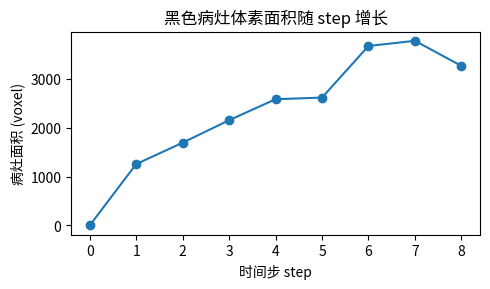

病灶面积序列: [0.0, 1255.0, 1693.0, 2153.0, 2582.0, 2616.0, 3671.0, 3777.0, 3263.0]


In [20]:
# ---------- 病灶面积随时间的增长曲线 ----------
src0 = frames[0].to(device)[0]
area = []
for k in range(frames.shape[0]):
    f = frames[k].to(device)[0]
    newly_dark = ((f < 0.22) & (src0 >= 0.22) & (src0 > 0.04)).float().sum()
    area.append(float(newly_dark))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(range(frames.shape[0]), area, marker='o')
ax.set_title('黑色病灶体素面积随 step 增长')
ax.set_xlabel('时间步 step'); ax.set_ylabel('病灶面积 (voxel)')
plt.tight_layout()
plt.show()
print('病灶面积序列:', [round(a, 1) for a in area])

病灶中心: (34, 37, 31)


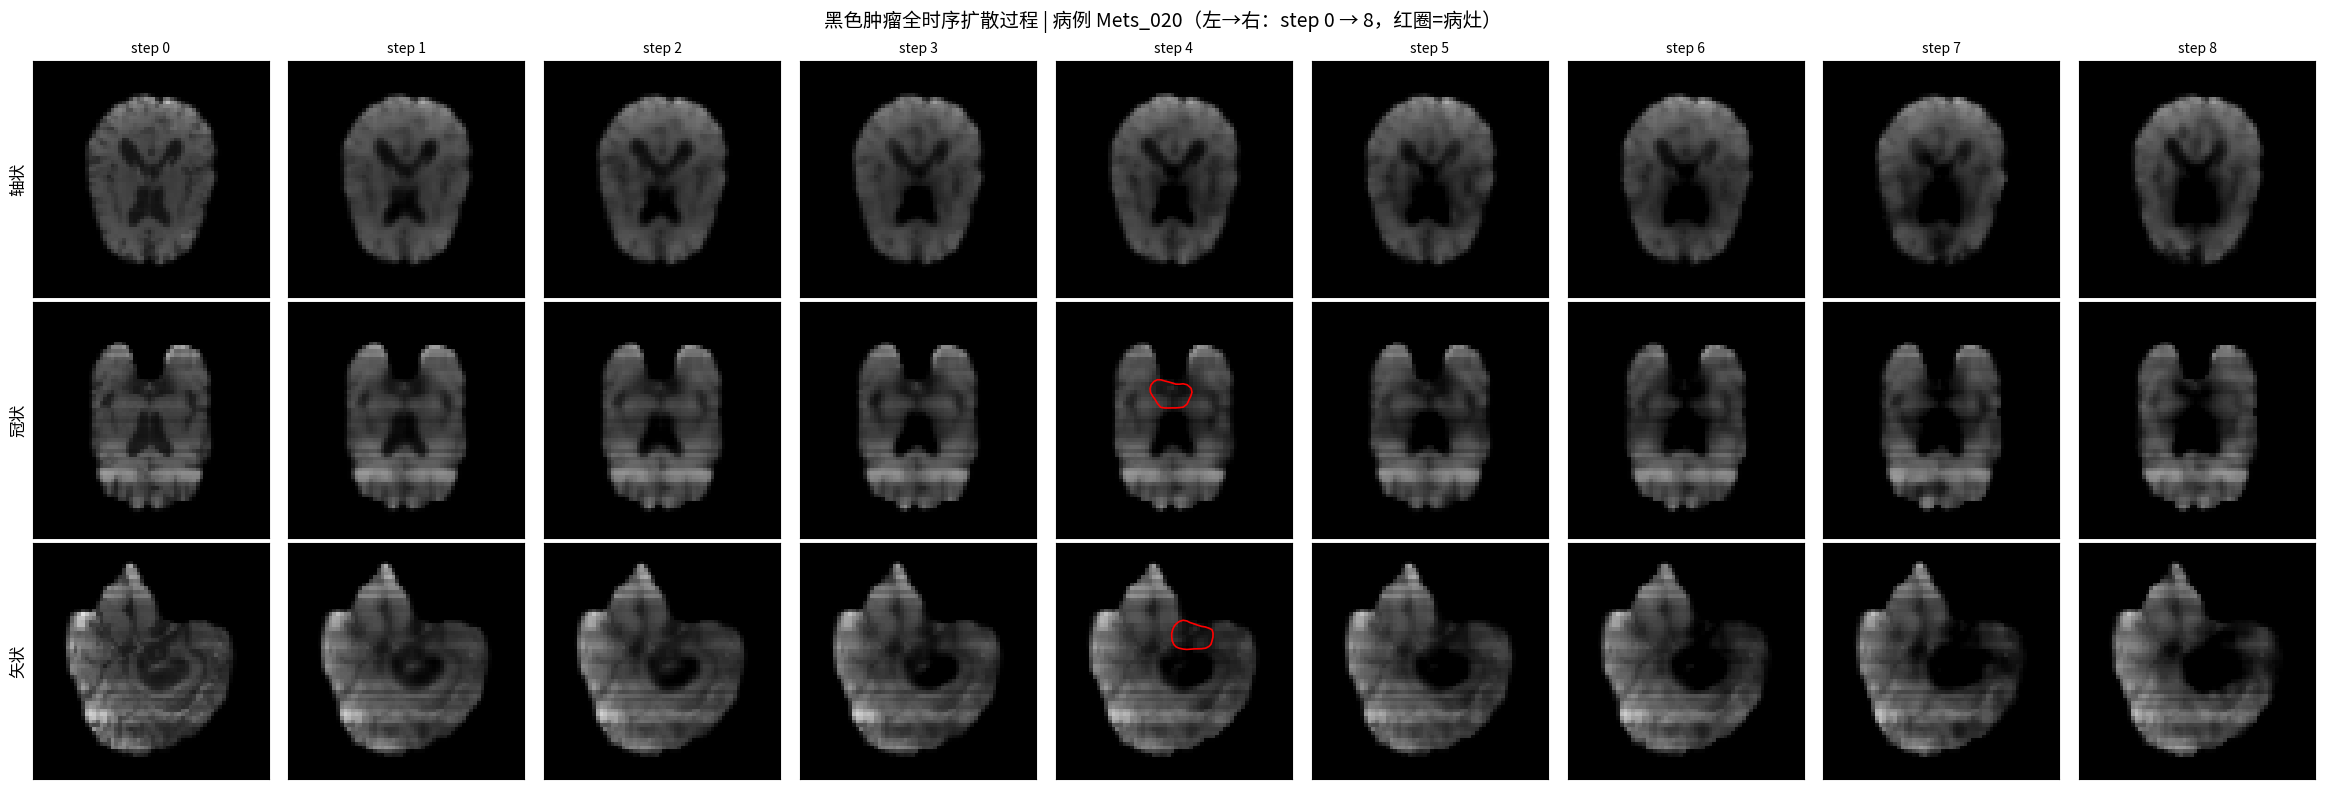

三视图时序大图已内联显示在上方


In [16]:
# ---------- 全时序三视图大图（核心交付） ----------
def view(vol, axis, z):
    if axis == 0:   # 轴状
        return vol[z, :, :].cpu().numpy()
    if axis == 1:   # 冠状
        return vol[:, z, :].cpu().numpy()
    return vol[:, :, z].cpu().numpy()  # 矢状

f = frames.cpu()
# 病灶中心（用于选切片）
lc = torch.stack(torch.where(dark_lesion_mask(frames[0].to(device)) > 0.5)).float().mean(dim=1).long().cpu()
z_ax, z_cor, z_sag = int(lc[0]), int(lc[1]), int(lc[2])
print('病灶中心:', (z_ax, z_cor, z_sag))

fig, axes = plt.subplots(3, GRID_STEPS + 1, figsize=(2.6*(GRID_STEPS+1), 8))
views = [('轴状', 0, z_ax), ('冠状', 1, z_cor), ('矢状', 2, z_sag)]
for r, (name, axis, z) in enumerate(views):
    for c in range(GRID_STEPS + 1):
        img = view(f[c][0], axis, z)
        axes[r, c].imshow(img, cmap='gray', vmin=0.0, vmax=0.75)
        if c == GRID_STEPS // 2:
            m = dark_lesion_mask(frames[c].to(device))
            m2 = view(m, axis, z)
            axes[r, c].contour(m2, levels=[0.5], colors='red', linewidths=1.2)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(f'step {c}', fontsize=10)
axes[0, 0].set_ylabel('轴状', fontsize=12)
axes[1, 0].set_ylabel('冠状', fontsize=12)
axes[2, 0].set_ylabel('矢状', fontsize=12)
fig.suptitle(f'黑色肿瘤全时序扩散过程 | 病例 {test_cases[case_idx].name}（左→右：step 0 → {GRID_STEPS}，红圈=病灶）', fontsize=14)
plt.tight_layout()
plt.show()
print('三视图时序大图已内联显示在上方')

In [11]:
print()
print('='*70)
print('全时序演化生成完成')
print('病例:', test_cases[case_idx].name)
print('帧数:', frames.shape[0], '| 每帧尺寸:', tuple(frames.shape[1:]))
print('输出:')
print('  - 三视图时序大图 / 病灶面积增长曲线：已内联显示在上方 cell')
print('  -', NOTEBOOK_DIR / 'tumor_sim_out/        （nii.gz 序列）')
print('='*70)


全时序演化生成完成
病例: Mets_020
帧数: 9 | 每帧尺寸: (1, 64, 64, 64)
输出:
  - 三视图时序大图 / 病灶面积增长曲线：已内联显示在上方 cell
  - /root/autodl-tmp/tumor_sim_out/        （nii.gz 序列）
